# Project 1 - EDA Report

- This report covers credit data about 150,000 borrowers from the Kaggle
  competition   ("Give Me Some Credit")
- The goal is to understand the data before building a model that predicts
  whether a borrower will have a serious delinquency within two years


# Load Data
  

In [6]:
import pandas as pd

df = pd.read_csv("../data/raw/cs-training.csv")
df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## Check dataset size

In [7]:
df.shape

(150000, 12)

## Check for missing values

In [8]:
df.isnull().sum()

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

## Data Quality Issues

- MonthlyIncome is missing for ~30K borrowers (19.8%), because the income was not recorded for them.
- NumberOfDependents is missing for ~4K borrowers (2.6%), because the number of dependents was not recorded.
- DebtRatio is above 1 for ~35K borrowers, with a max of 329,664 (median 0.37), so a few extreme values distort the average.
- NumberOfTimes90DaysLate has 269 rows with the value 96 or 98, far above the next highest value (17). These look like special codes, not real counts.
- 609 rows are exact duplicates.
- Column names like NumberOfTime30-59DaysPastDueNotWorse are long and contain hyphens, which causes problems in SQL.
- "Unnamed: 0" is only a row index and carries no information.

In [9]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing)
print((missing / len(df) * 100).round(1))

MonthlyIncome         29731
NumberOfDependents     3924
dtype: int64
MonthlyIncome         19.8
NumberOfDependents     2.6
dtype: float64


In [10]:
print("Rows with DebtRatio > 1:", (df["DebtRatio"] > 1).sum())
print("Max:", df["DebtRatio"].max())
print("Median:", round(df["DebtRatio"].median(), 2))
print("Mean:", round(df["DebtRatio"].mean(), 1))

Rows with DebtRatio > 1: 35137
Max: 329664.0
Median: 0.37
Mean: 353.0


In [11]:
print(df["NumberOfTimes90DaysLate"].value_counts().sort_index().tail(6))

odd = df[df["NumberOfTimes90DaysLate"] >= 96]
print("Rows with 96 or 98:", len(odd))
print("Default rate in these rows:", round(odd["SeriousDlqin2yrs"].mean() * 100, 1), "%")
print("Default rate overall:", round(df["SeriousDlqin2yrs"].mean() * 100, 1), "%")

NumberOfTimes90DaysLate
13      4
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64
Rows with 96 or 98: 269
Default rate in these rows: 54.6 %
Default rate overall: 6.7 %


In [12]:
print("Duplicate rows:", df.drop(columns="Unnamed: 0").duplicated().sum())
print([c for c in df.columns if "-" in c])
print(df["Unnamed: 0"].head())

Duplicate rows: 609
['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse']
0    1
1    2
2    3
3    4
4    5
Name: Unnamed: 0, dtype: int64


## Key Insights and Visualizations

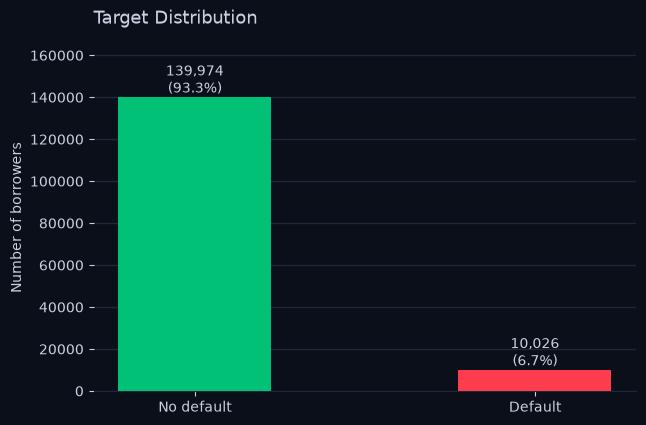

In [15]:
import matplotlib.pyplot as plt

counts = df["SeriousDlqin2yrs"].value_counts().sort_index()
labels = ["No default", "Default"]
colors = ["#00C176", "#FF3B4E"]   # أخضر وأحمر مثل الأسهم

BG, GRID, TEXT = "#0B0F1A", "#1E2638", "#C9D1E0"

fig, ax = plt.subplots(figsize=(7, 4.5), facecolor=BG)
ax.set_facecolor(BG)

bars = ax.bar(labels, counts.values, color=colors, width=0.45, zorder=3)

for bar, value in zip(bars, counts.values):
    pct = value / counts.sum() * 100
    ax.text(bar.get_x() + bar.get_width() / 2, value,
            f"{value:,}\n({pct:.1f}%)", ha="center", va="bottom",
            color=TEXT, fontsize=10)

ax.grid(axis="y", color=GRID, linewidth=1, zorder=0)
ax.set_title("Target Distribution", color=TEXT, fontsize=13, loc="left", pad=15)
ax.set_ylabel("Number of borrowers", color=TEXT)
ax.set_ylim(0, counts.max() * 1.18)
ax.tick_params(colors=TEXT)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
plt.show()